In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import darsh as da

In [3]:
df=pd.read_csv("data/Dataset.csv")

In [4]:
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [5]:
df.describe()

,release_year
count,8790.000000
mean,2014.183163
std,8.825466
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB


In [9]:
df.isna().sum()

show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.columns = df.columns.str.strip() 
df.columns = df.columns.str.lower().str.replace(" ", "_") 
for col in df.select_dtypes(include="object").columns:
  df[col] = df[col].str.strip()

In [13]:
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [14]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage)

show_id         0.0
type            0.0
title           0.0
director        0.0
country         0.0
date_added      0.0
release_year    0.0
rating          0.0
duration        0.0
listed_in       0.0
dtype: float64


In [15]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", "_", regex=True)
)

In [16]:
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].str.strip()
    df[col] = df[col].str.replace(r"\s+", " ", regex=True)

In [18]:
if "rating" in df.columns:
    df["rating"] = df["rating"].str.upper()

    df["rating"] = df["rating"].replace({
        "TV MA": "TV-MA",
        "TV 14": "TV-14",
        "TV PG": "TV-PG",
        "PG 13": "PG-13"
    })

In [19]:
if "type" in df.columns:
    df["type"] = df["type"].str.lower()

    df["type"] = df["type"].replace({
        "movie": "Movie",
        "movies": "Movie",
        "tv show": "TV Show",
        "tv shows": "TV Show",
        "tv series": "TV Show"
    })

In [21]:
print(df["type"].value_counts())



type
Movie      6126
TV Show    2664
Name: count, dtype: int64


In [22]:
print(df["rating"].value_counts())



rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64


In [23]:
print(df["country"].value_counts().head(10))

country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64


In [24]:
from pathlib import Path

Path("data").mkdir(exist_ok=True)

df.to_csv("data/Cleaned_Netflix.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [25]:
cleaned_df = pd.read_csv("data/Cleaned_Netflix.csv")

print("Final Shape:", cleaned_df.shape)
print("Remaining Duplicates:", cleaned_df.duplicated().sum())

display(cleaned_df.head())

Final Shape: (8790, 10)
Remaining Duplicates: 0


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


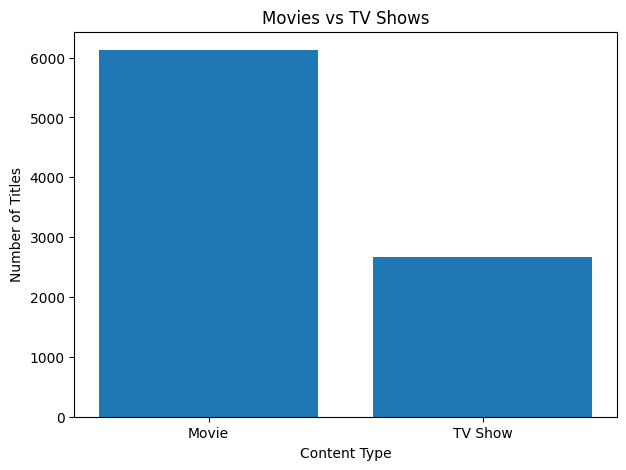

In [27]:
type_count = df["type"].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(type_count.index, type_count.values)

plt.title("Movies vs TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

plt.show()

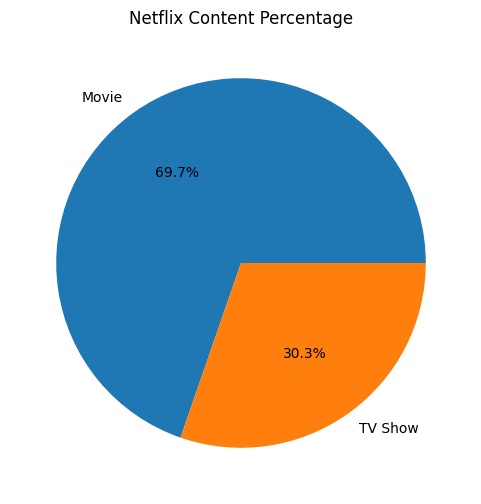

In [28]:
type_count = df["type"].value_counts()

plt.figure(figsize=(6, 6))

plt.pie(
    type_count.values,
    labels=type_count.index,
    autopct="%1.1f%%"
)

plt.title("Netflix Content Percentage")
plt.show()

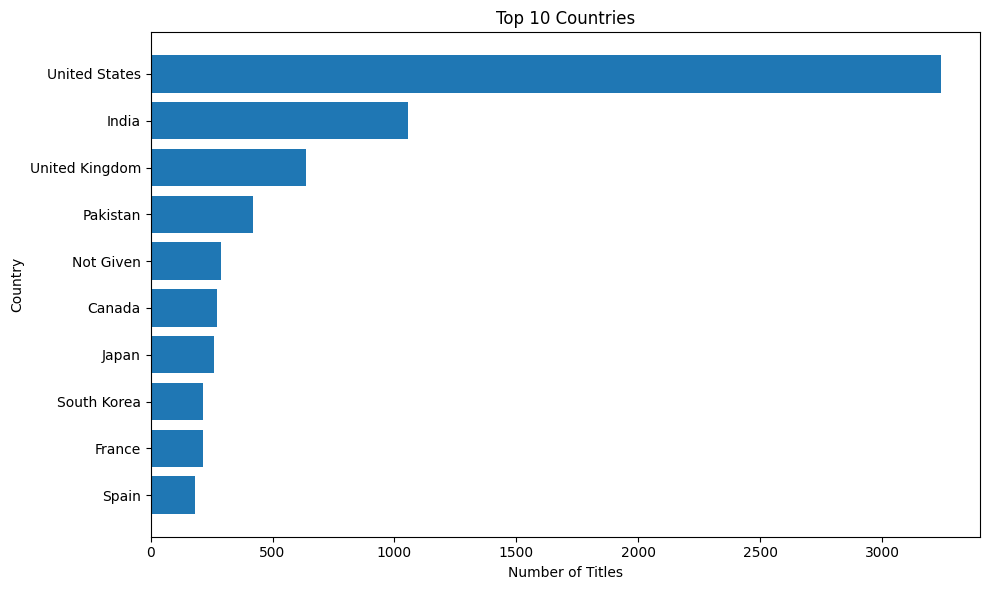

In [29]:
country_count = (
    df["country"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 6))

plt.barh(country_count.index, country_count.values)

plt.title("Top 10 Countries")
plt.xlabel("Number of Titles")
plt.ylabel("Country")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

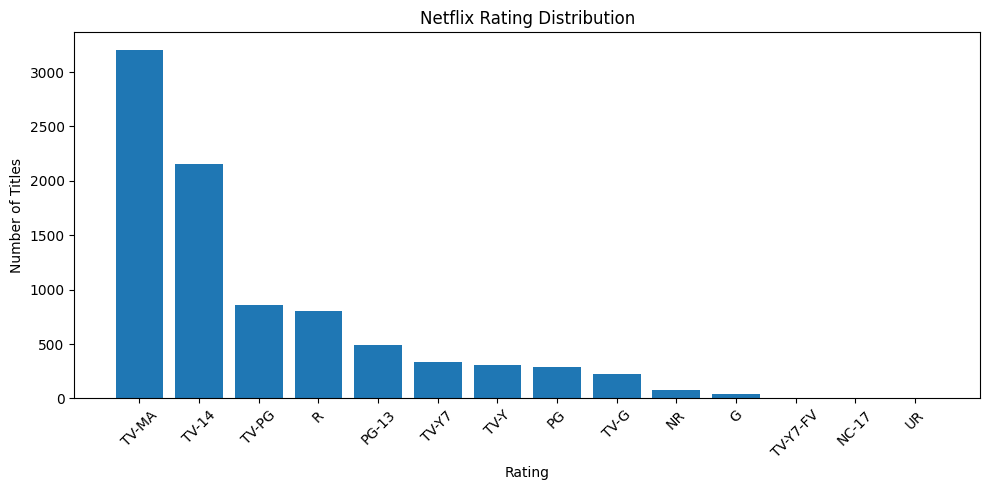

In [30]:
rating_count = df["rating"].value_counts()

plt.figure(figsize=(10, 5))

plt.bar(rating_count.index, rating_count.values)

plt.title("Netflix Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

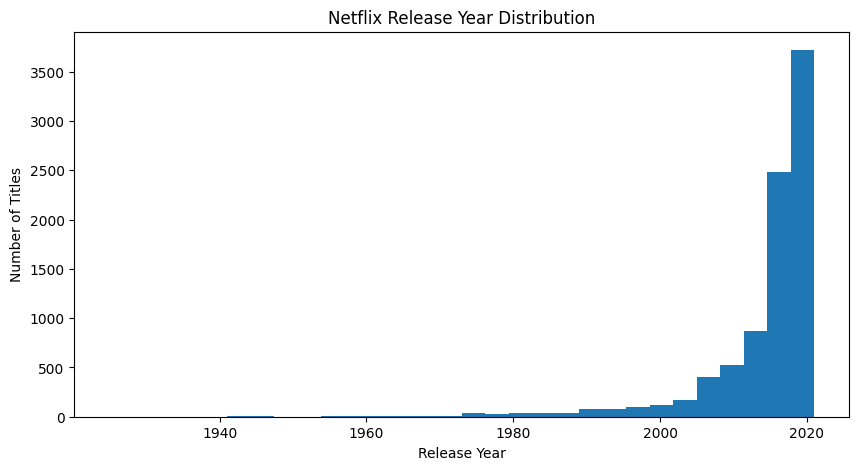

In [31]:
plt.figure(figsize=(10, 5))

plt.hist(df["release_year"].dropna(), bins=30)

plt.title("Netflix Release Year Distribution")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.show()

In [33]:
df["duration_value"] = pd.to_numeric(
    df["duration"].astype(str).str.extract(r"(\d+)")[0],
    errors="coerce"
)

In [34]:
df["type_encoded"] = df["type"].map({
    "Movie": 0,
    "TV Show": 1
})

In [35]:
graph_df = df.dropna(
    subset=["release_year", "duration_value", "type_encoded"]
)

In [37]:
da.scatter_3d(
    graph_df,
    x="release_year",
    y="duration_value",
    z="type_encoded"
)

In [38]:
movies = df[df["type"] == "Movie"].copy()

movies["duration_value"] = pd.to_numeric(
    movies["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

movies["release_year"] = pd.to_numeric(
    movies["release_year"],
    errors="coerce"
)

movies["rating_encoded"] = pd.factorize(
    movies["rating"]
)[0]

movies = movies.dropna(
    subset=["release_year", "duration_value"]
)

da.scatter_3d(
    movies,
    x="release_year",
    y="duration_value",
    z="rating_encoded"
)

In [40]:
movies.darsh.scatter_3d(
    x="release_year",
    y="duration_value",
    z="rating_encoded"
)